# 04 训练集与测试集的特征分布差异
对应任务：**检查训练集与测试集的特征分布差异**
要回答的问题不是"看起来像不像"，而是：**有没有变量在 train/test 之间系统性地不同**。
如果存在，那么
- 训练集上学到的规律在 test 上可能不成立，本地 CV 会高估；
- 或者反过来说，某些特征可以"认出"样本来自哪一边，说明划分不随机。
三把尺子，从粗到细：
1. 逐列缺失率对比
2. 分类变量的分布对比 + 卡方检验；数值变量的分布对比 + KS 检验
3. **对抗验证（adversarial validation）**：训练一个模型区分"这条来自 train 还是 test"，
   AUC 接近 0.5 说明当前模型未发现明显可区分信号，不能证明分布完全相同。



In [1]:
import os
import sys
from pathlib import Path

START = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ROOT = next(p for p in [START, *START.parents]
            if (p / "src" / "preprocess.py").is_file())
sys.path.insert(0, str(ROOT))
from src.paths import EXPERIMENTS_DIR, FIGURES_DIR
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplcache"))

FIG = FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import preprocess as pp

matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
matplotlib.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Microsoft YaHei")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

train_raw, test_raw = pp.load_raw()
train = pp.build_features(train_raw.copy())
test = pp.build_features(test_raw.copy())
print("train:", train.shape, "| test:", test.shape)



train: (8693, 41) | test: (4277, 40)


## 4.1 缺失率对比
最粗的一层：如果某个字段在一侧的缺失率明显更高，那这侧的数据质量就不同。



              train缺失率%  test缺失率%  差值(百分点)
Age               2.059     2.128    0.069
Cabin             2.289     2.338    0.049
CryoSleep         2.496     2.174   -0.322
Destination       2.094     2.151    0.057
FoodCourt         2.105     2.478    0.373
HomePlanet        2.312     2.034   -0.278
Name              2.301     2.198   -0.103
PassengerId       0.000     0.000    0.000
RoomService       2.082     1.917   -0.165
ShoppingMall      2.393     2.291   -0.101
Spa               2.105     2.361    0.256
Transported       0.000       NaN      NaN
VIP               2.335     2.174   -0.161
VRDeck            2.163     1.870   -0.292

最大差值: 0.373 个百分点


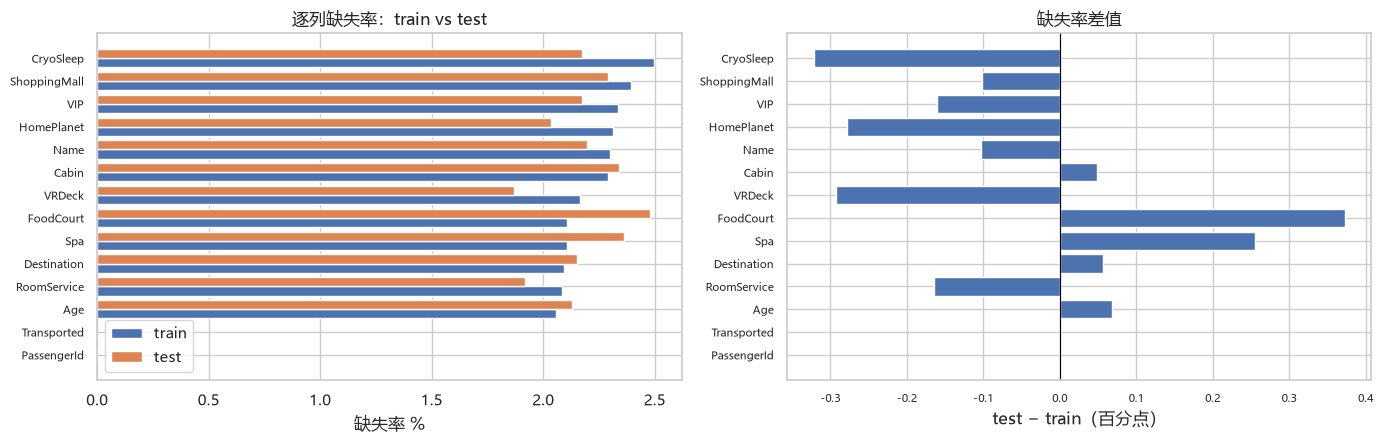

In [2]:
mtr = train_raw.isna().mean() * 100
mte = test_raw.isna().mean() * 100
cmp_miss = pd.DataFrame({"train缺失率%": mtr, "test缺失率%": mte})
cmp_miss["差值(百分点)"] = (cmp_miss["test缺失率%"] - cmp_miss["train缺失率%"]).round(3)
cmp_miss = cmp_miss.round(3)
print(cmp_miss.to_string())
print("\n最大差值: %.3f 个百分点" % cmp_miss["差值(百分点)"].abs().max())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
order = cmp_miss["train缺失率%"].sort_values().index
pos = np.arange(len(order))
axes[0].barh(pos - 0.2, cmp_miss.loc[order, "train缺失率%"], height=0.4, label="train")
axes[0].barh(pos + 0.2, cmp_miss.loc[order, "test缺失率%"], height=0.4, label="test")
axes[0].set_yticks(pos, order, fontsize=8)
axes[0].set_xlabel("缺失率 %")
axes[0].set_title("逐列缺失率：train vs test")
axes[0].legend()

axes[1].barh(order, cmp_miss.loc[order, "差值(百分点)"], color="#4C72B0")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("test − train（百分点）")
axes[1].set_title("缺失率差值")
axes[1].tick_params(labelsize=8)
plt.tight_layout()
fig.savefig(FIG / "04_missing_rate_diff.png", dpi=140, bbox_inches="tight")
plt.show()



## 4.2 分类变量：分布对比 + 卡方检验
卡方检验的原假设是"该变量在 train/test 中同分布"。
p 值大 → 没有证据说明不同；p 值小 → 分布有系统性差异。



         变量  类别数     卡方  自由度     p值    结论
 HomePlanet    4  5.086    3 0.1656 无显著差异
Destination    4  2.079    3 0.5561 无显著差异
       Deck    9 11.562    8 0.1719 无显著差异
       Side    3  0.188    2 0.9103 无显著差异
  CryoSleep    3  2.668    2 0.2634 无显著差异
        VIP    3  4.736    2 0.0937 无显著差异
    AgeBand    9 14.996    8 0.0592 无显著差异


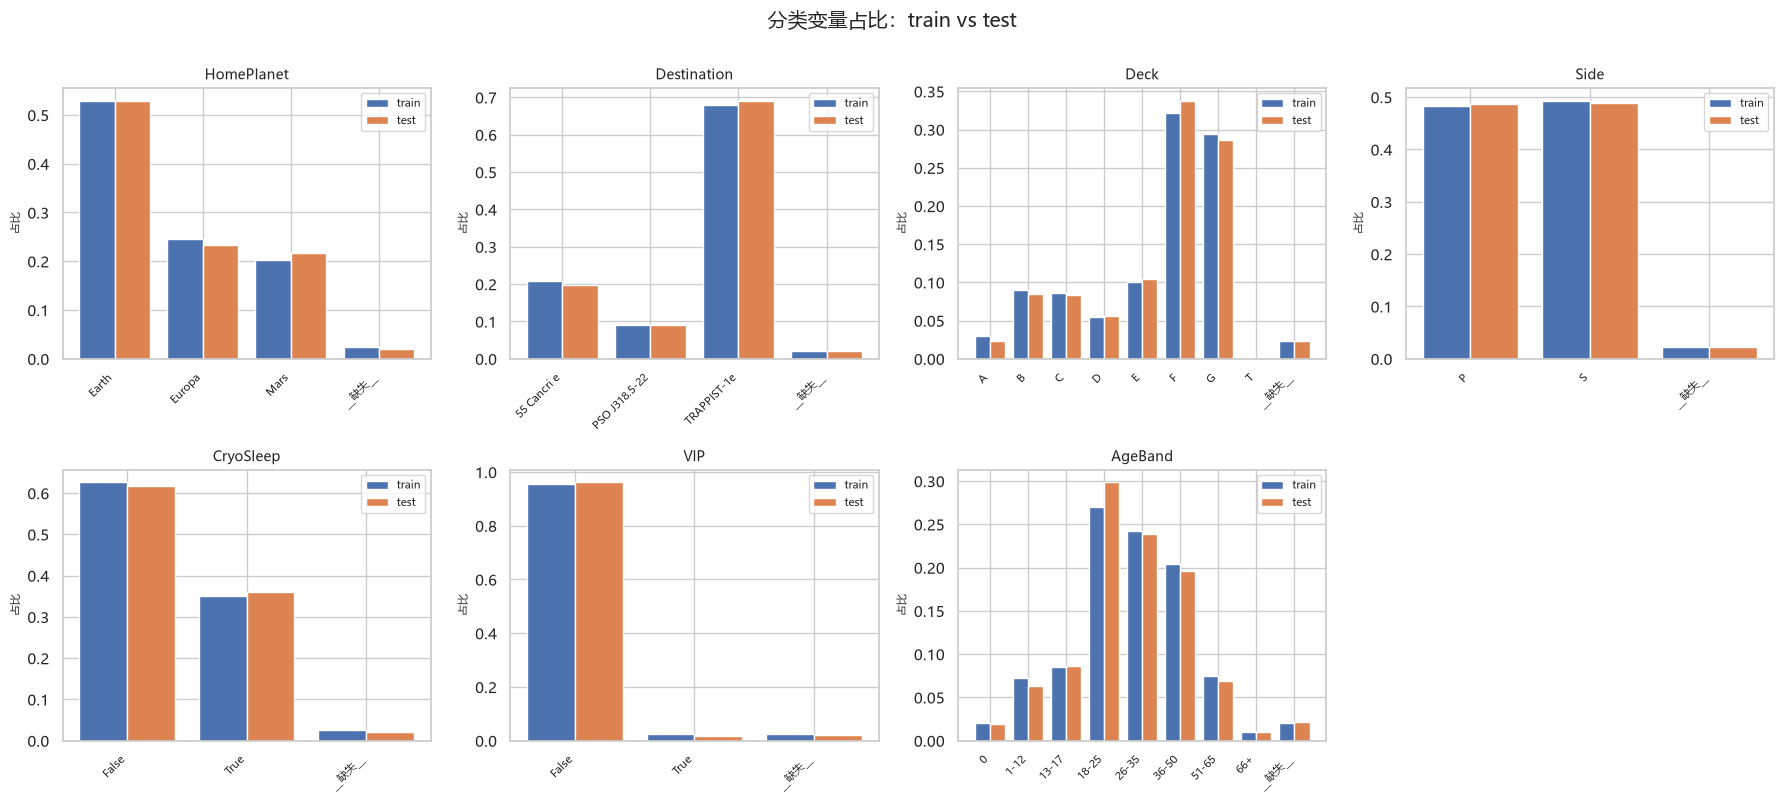

In [3]:
cat_cols = ["HomePlanet", "Destination", "Deck", "Side", "CryoSleep", "VIP", "AgeBand"]
rows = []
for col in cat_cols:
    # 统一转成字符串再统计：CryoSleep/VIP 是可空布尔，混着字符串会无法排序
    a = train[col].astype(object).fillna("__缺失__").astype(str).value_counts()
    b = test[col].astype(object).fillna("__缺失__").astype(str).value_counts()
    idx = sorted(set(a.index) | set(b.index))
    tab = np.array([[a.get(k, 0) for k in idx], [b.get(k, 0) for k in idx]])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    rows.append({
        "变量": col,
        "类别数": len(idx),
        "卡方": round(chi2, 3),
        "自由度": dof,
        "p值": round(p, 4),
        "结论": "无显著差异" if p > 0.05 else "有差异(p<0.05)",
    })
chi_tbl = pd.DataFrame(rows)
print(chi_tbl.to_string(index=False))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    a = train[col].astype(object).fillna("__缺失__").astype(str).value_counts(normalize=True)
    b = test[col].astype(object).fillna("__缺失__").astype(str).value_counts(normalize=True)
    idx = sorted(set(a.index) | set(b.index))
    pos = np.arange(len(idx))
    ax.bar(pos - 0.2, [a.get(k, 0) for k in idx], width=0.4, label="train")
    ax.bar(pos + 0.2, [b.get(k, 0) for k in idx], width=0.4, label="test")
    ax.set_xticks(pos, idx, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{col}", fontsize=10)
    ax.set_ylabel("占比", fontsize=8)
    ax.legend(fontsize=8)
axes.ravel()[-1].axis("off")
plt.suptitle("分类变量占比：train vs test", y=1.0)
plt.tight_layout()
fig.savefig(FIG / "04_categorical_distribution.png", dpi=140, bbox_inches="tight")
plt.show()



## 4.3 数值变量：分布对比 + KS 检验
KS 检验比较两条累积分布曲线，对形状差异（不只是均值）敏感。
同时看分位数：**均值相同也可能分布形状不同**。



In [4]:
num_cols = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck",
            "TotalSpend", "CabinNum"]
rows = []
for col in num_cols:
    a = pd.to_numeric(train[col], errors="coerce").dropna()
    b = pd.to_numeric(test[col], errors="coerce").dropna()
    ks, p = stats.ks_2samp(a, b)
    rows.append({
        "变量": col,
        "train均值": round(a.mean(), 2), "test均值": round(b.mean(), 2),
        "train中位数": round(a.median(), 1), "test中位数": round(b.median(), 1),
        "KS统计量": round(ks, 4), "p值": round(p, 4),
        "结论": "无显著差异" if p > 0.05 else "有差异(p<0.05)",
    })
ks_tbl = pd.DataFrame(rows)
print(ks_tbl.to_string(index=False))



          变量  train均值  test均值  train中位数  test中位数  KS统计量     p值    结论
         Age    28.83   28.66      27.0     26.0 0.0190 0.2564 无显著差异
 RoomService   224.69  219.27       0.0      0.0 0.0082 0.9910 无显著差异
   FoodCourt   458.08  439.48       0.0      0.0 0.0066 0.9996 无显著差异
ShoppingMall   173.73  177.30       0.0      0.0 0.0091 0.9735 无显著差异
         Spa   311.14  303.05       0.0      0.0 0.0082 0.9902 无显著差异
      VRDeck   304.85  310.71       0.0      0.0 0.0143 0.6045 无显著差异
  TotalSpend  1440.87 1417.68     716.0    714.0 0.0141 0.6109 无显著差异
    CabinNum   600.37  610.18     427.0    442.0 0.0205 0.1850 无显著差异


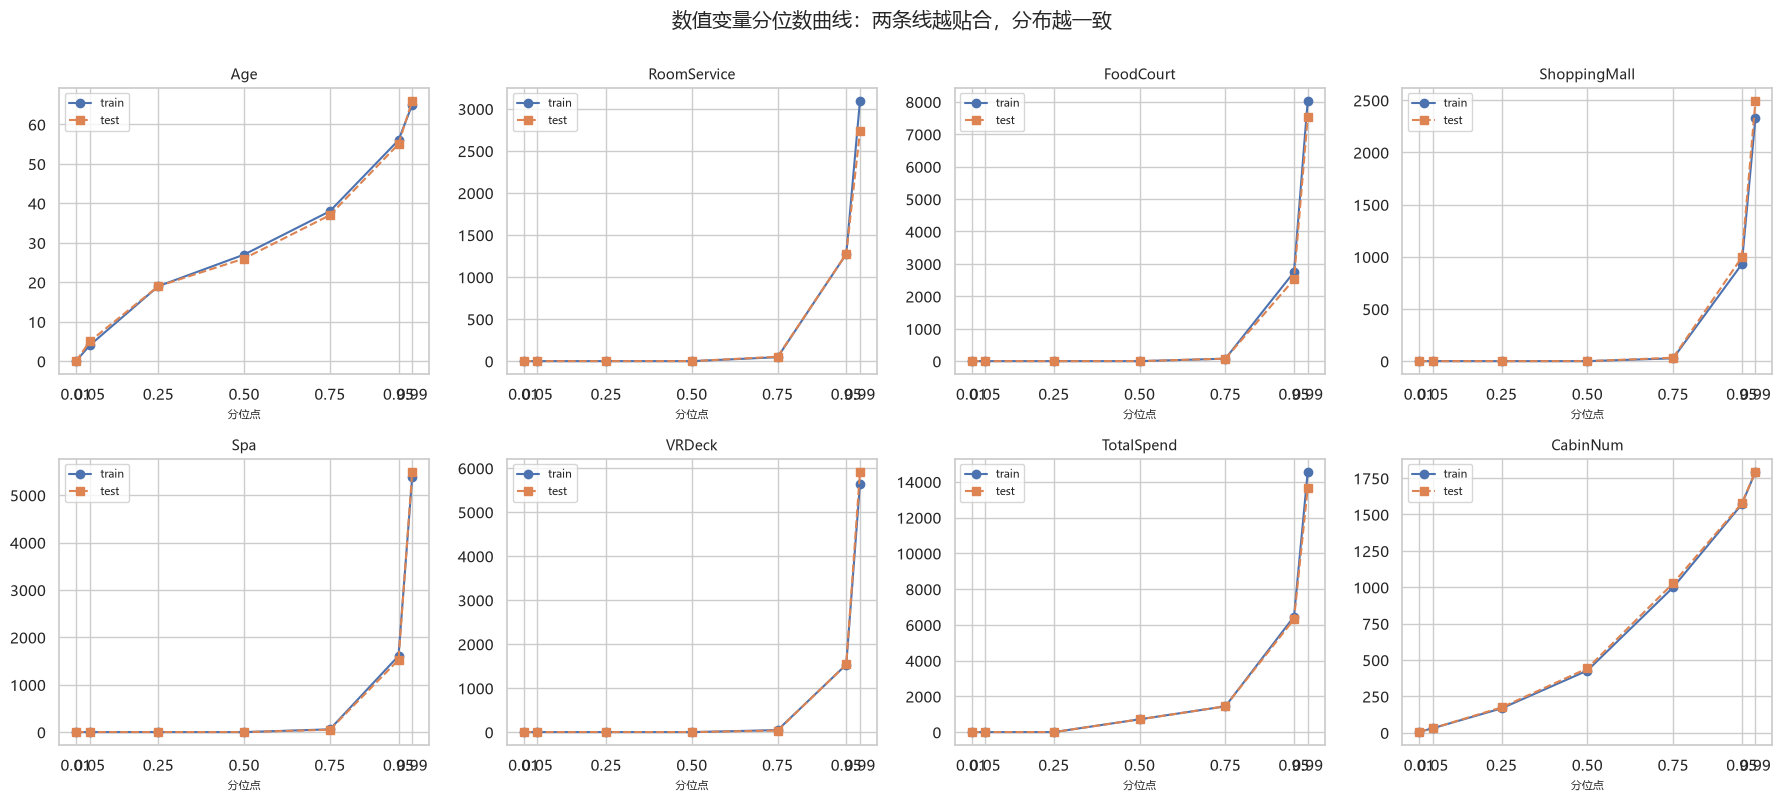

In [5]:
q = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    a = pd.to_numeric(train[col], errors="coerce").dropna()
    b = pd.to_numeric(test[col], errors="coerce").dropna()
    qa, qb = np.quantile(a, q), np.quantile(b, q)
    ax.plot(q, qa, "o-", label="train")
    ax.plot(q, qb, "s--", label="test")
    ax.set_title(col, fontsize=10)
    ax.set_xticks(q)
    ax.set_xlabel("分位点", fontsize=8)
    ax.legend(fontsize=8)
plt.suptitle("数值变量分位数曲线：两条线越贴合，分布越一致", y=1.0)
plt.tight_layout()
fig.savefig(FIG / "04_numeric_quantile.png", dpi=140, bbox_inches="tight")
plt.show()



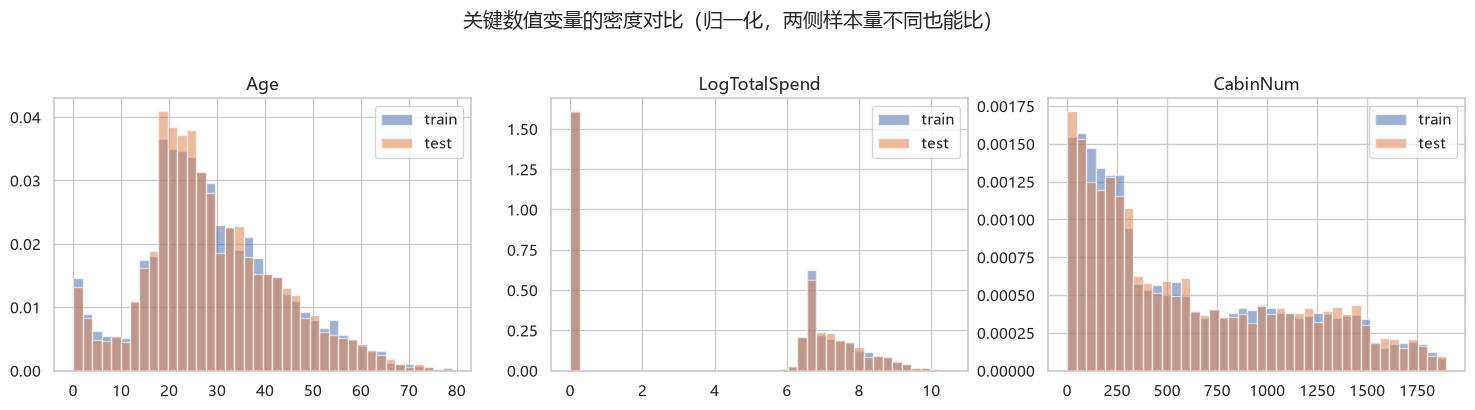

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "LogTotalSpend", "CabinNum"]):
    a = pd.to_numeric(train[col], errors="coerce").dropna()
    b = pd.to_numeric(test[col], errors="coerce").dropna()
    bins = np.histogram_bin_edges(pd.concat([a, b]), bins=40)
    ax.hist(a, bins=bins, alpha=0.55, density=True, label="train")
    ax.hist(b, bins=bins, alpha=0.55, density=True, label="test")
    ax.set_title(col)
    ax.legend()
plt.suptitle("关键数值变量的密度对比（归一化，两侧样本量不同也能比）", y=1.02)
plt.tight_layout()
fig.savefig(FIG / "04_numeric_density.png", dpi=140, bbox_inches="tight")
plt.show()



## 4.4 对抗验证（adversarial validation）
把 train/test 混在一起，训练一个模型预测"这条来自哪一边"。
- **AUC ≈ 0.5** → 当前模型难以区分；没有发现明显分布差异，
  但仍需正确的分组验证，不能单凭此值保证本地 CV 与榜单一致。
- **AUC 明显 > 0.5** → 存在系统性差异，需要找出是哪些变量造成的。
这一步的标签是"数据来源"，不是 `Transported`，所以随机切分即可，不需要按组。
同时给出**置换重要性**，直接指出"哪个变量的分布差异最大"。



对抗验证样本: (12970, 65) | 来自 test 的比例: 0.330


对抗验证 AUC（5 折）: [0.7447 0.7447 0.7379 0.7395 0.7351] | 均值 0.7404


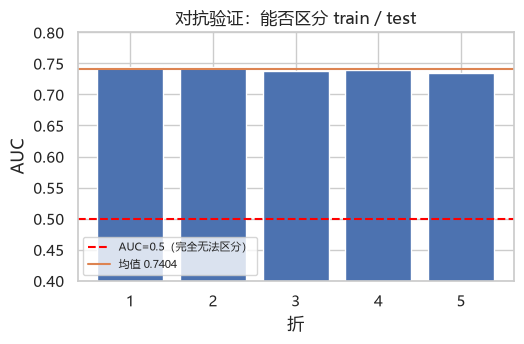

In [7]:
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_all = pd.concat([
    pp.make_model_matrix(pp.Preprocessor("indicator").fit_transform(train)),
    pp.make_model_matrix(pp.Preprocessor("indicator").fit(test).transform(test)),
], ignore_index=True)
y_domain = np.r_[np.zeros(len(train), dtype=int), np.ones(len(test), dtype=int)]
print("对抗验证样本:", X_all.shape, "| 来自 test 的比例: %.3f" % y_domain.mean())

clf = HistGradientBoostingClassifier(random_state=0, max_iter=200, learning_rate=0.06)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
with joblib.parallel_backend("sequential"):
    aucs = cross_val_score(clf, X_all, y_domain, cv=cv, scoring="roc_auc", n_jobs=1)
print("对抗验证 AUC（5 折）:", np.round(aucs, 4), "| 均值 %.4f" % aucs.mean())

fig, ax = plt.subplots(figsize=(5.4, 3.6))
ax.bar(range(1, 6), aucs, color="#4C72B0")
ax.axhline(0.5, ls="--", color="red", label="AUC=0.5（完全无法区分）")
ax.axhline(aucs.mean(), ls="-", color="#DD8452", label=f"均值 {aucs.mean():.4f}")
ax.set_ylim(0.4, max(0.8, aucs.max() + 0.04))
ax.set_xlabel("折")
ax.set_ylabel("AUC")
ax.set_title("对抗验证：能否区分 train / test")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "04_adversarial_auc.png", dpi=140, bbox_inches="tight")
plt.show()



置换重要性 Top 15（对区分 train/test 的贡献）：
               特征     重要性     标准差
      SurnameSize 0.27157 0.00416
        GroupSize 0.04621 0.00187
              Age 0.03093 0.00079
 HomePlanet_Earth 0.02485 0.00141
          IsAlone 0.02243 0.00045
     IsMixedGroup 0.01961 0.00074
           Age_na 0.01210 0.00117
HomePlanet_Europa 0.01150 0.00123
           Side_P 0.01016 0.00070
          Name_na 0.00997 0.00045
       TotalSpend 0.00984 0.00041
      LuxurySpend 0.00871 0.00037
     ShoppingMall 0.00847 0.00049
              Spa 0.00827 0.00036
      LuxuryShare 0.00753 0.00030


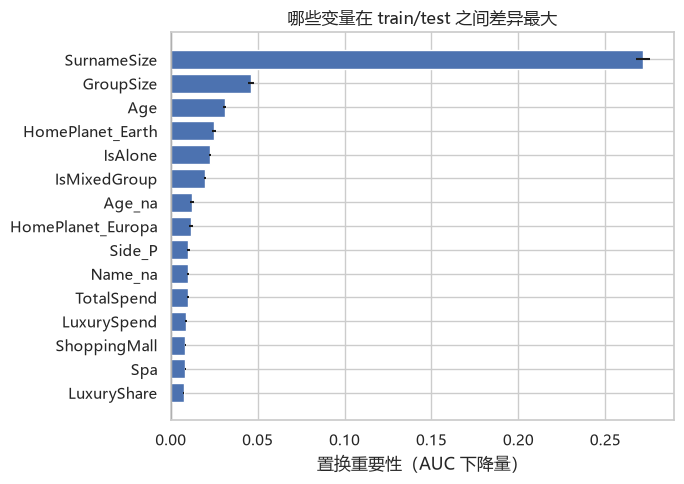

In [8]:
with joblib.parallel_backend("sequential"):
    clf.fit(X_all, y_domain)
    imp = permutation_importance(clf, X_all, y_domain, n_repeats=5,
                                 random_state=0, scoring="roc_auc", n_jobs=1)
imp_tbl = (pd.DataFrame({"特征": X_all.columns, "重要性": imp.importances_mean,
                         "标准差": imp.importances_std})
           .sort_values("重要性", ascending=False).head(15).round(5))
print("置换重要性 Top 15（对区分 train/test 的贡献）：")
print(imp_tbl.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
t = imp_tbl.iloc[::-1]
ax.barh(t["特征"], t["重要性"], xerr=t["标准差"], color="#4C72B0")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("置换重要性（AUC 下降量）")
ax.set_title("哪些变量在 train/test 之间差异最大")
plt.tight_layout()
fig.savefig(FIG / "04_adversarial_importance.png", dpi=140, bbox_inches="tight")
plt.show()



### 诊断：为什么派生特征能区分数据来源？
置换重要性把矛头直接指向 `SurnameSize`（重要性约 0.27，比第二名高一个数量级）。
这个特征是"同一姓氏总共有多少人"，而它是在 **train 和 test 里各算各的**。
- 组号 `gggg` 在两边**不重叠**（交集 0），所以 `GroupSize` 怎么算都一样；
- 但**姓氏是重叠的**：1536 个姓氏同时出现在两边。
  train 有 8693 人、test 只有 4277 人，同一个姓氏在 train 里数出来的计数天然更大。
于是这个特征变成了**"我来自哪个数据集"的指纹**。下面用数据坐实。



SurnameSize 取值分布（各数据集单独计算）：
             train 人数  test 人数
SurnameSize                   
1.0               582      723
2.0               800      950
3.0              1164      792
4.0              1280      696
5.0              1280      430
6.0              1038      270
7.0               833      168
8.0               544      136
9.0               315       54
10.0              300       20
11.0              275       11
12.0               84        0

均值: train 5.326  |  test 3.505   -> 同一个人口统计量，两侧差了一大截
组号交集: 0（不重叠，GroupSize 不受影响）
姓氏交集: 1536 个 -> 覆盖 train 6137 人、test 3759 人


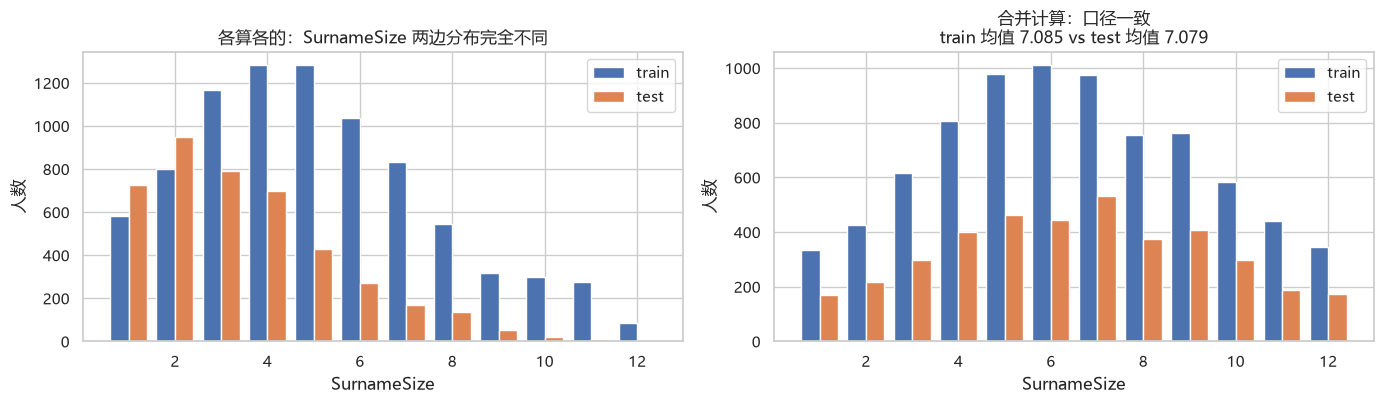

In [9]:
sv = pd.DataFrame({
    "train 人数": train.SurnameSize.value_counts().sort_index(),
    "test 人数": test.SurnameSize.value_counts().sort_index(),
}).fillna(0).astype(int)

s_tr = set(train.Surname.dropna())
s_te = set(test.Surname.dropna())
inter = s_tr & s_te

print("SurnameSize 取值分布（各数据集单独计算）：")
print(sv.head(12).to_string())
print("\n均值: train %.3f  |  test %.3f   -> 同一个人口统计量，两侧差了一大截"
      % (train.SurnameSize.mean(), test.SurnameSize.mean()))
print("组号交集: %d（不重叠，GroupSize 不受影响）" % len(set(train.GroupId) & set(test.GroupId)))
print("姓氏交集: %d 个 -> 覆盖 train %d 人、test %d 人"
      % (len(inter), int(train.Surname.isin(inter).sum()), int(test.Surname.isin(inter).sum())))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ks = np.arange(1, 13)
axes[0].bar(ks - 0.2, sv["train 人数"].reindex(ks, fill_value=0), width=0.4, label="train")
axes[0].bar(ks + 0.2, sv["test 人数"].reindex(ks, fill_value=0), width=0.4, label="test")
axes[0].set_xlabel("SurnameSize")
axes[0].set_ylabel("人数")
axes[0].set_title("各算各的：SurnameSize 两边分布完全不同")
axes[0].legend()

fix_m = pp.build_features_combined(train_raw.copy(), test_raw.copy())
f_tr, f_te = fix_m
sv2 = pd.DataFrame({
    "train 人数": f_tr.SurnameSize.value_counts().sort_index(),
    "test 人数": f_te.SurnameSize.value_counts().sort_index(),
}).fillna(0).astype(int)
axes[1].bar(ks - 0.2, sv2["train 人数"].reindex(ks, fill_value=0), width=0.4, label="train")
axes[1].bar(ks + 0.2, sv2["test 人数"].reindex(ks, fill_value=0), width=0.4, label="test")
axes[1].set_xlabel("SurnameSize")
axes[1].set_ylabel("人数")
axes[1].set_title("合并计算：口径一致\ntrain 均值 %.3f vs test 均值 %.3f"
                  % (f_tr.SurnameSize.mean(), f_te.SurnameSize.mean()))
axes[1].legend()
plt.tight_layout()
fig.savefig(FIG / "04_surnamesize_leak.png", dpi=140, bbox_inches="tight")
plt.show()



修复方式：**把 train 和 test 拼起来算派生特征，再拆回去**
（`preprocess.build_features_combined`）。组号不跨集，所以这样做不会把
test 的信息带进 train；用到的只是"test 也有这些公开列"这一事实，不涉及 `Transported`。



① 各算各的（有问题的做法）                       AUC=0.7404 ± 0.0042


② 合并计算（推荐做法）                         AUC=0.5505 ± 0.0112


③ 去掉姓氏规模类特征                          AUC=0.5197 ± 0.0166


④ 只用原始列                              AUC=0.5230 ± 0.0120


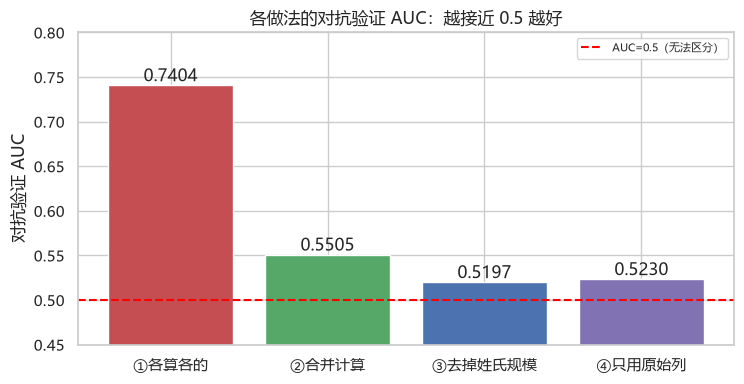

In [10]:
auc_results = []


def adv_auc(ftr, fte, label=""):
    X = pd.concat([
        pp.make_model_matrix(pp.Preprocessor("indicator").fit_transform(ftr)),
        pp.make_model_matrix(pp.Preprocessor("indicator").fit(fte).transform(fte)),
    ], ignore_index=True)
    y = np.r_[np.zeros(len(ftr), dtype=int), np.ones(len(fte), dtype=int)]
    m = HistGradientBoostingClassifier(random_state=0, max_iter=200, learning_rate=0.06)
    with joblib.parallel_backend("sequential"):
        auc = cross_val_score(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                              scoring="roc_auc", n_jobs=1)
    print(f"{label:36s} AUC={auc.mean():.4f} ± {auc.std(ddof=1):.4f}")
    auc_results.append({"方案": label, "AUC均值": float(auc.mean()),
                        "标准差": float(auc.std(ddof=1))})
    return auc.mean()


auc_before = adv_auc(train, test, "① 各算各的（有问题的做法）")
auc_after = adv_auc(f_tr, f_te, "② 合并计算（推荐做法）")

drop_cols = ["SurnameSize", "SurnameCount", "GroupSize", "IsAlone", "IsMixedGroup",
             "GroupSurnameCount", "GroupPos", "GroupNum"]
raw_cols = ["HomePlanet", "CryoSleep", "Cabin", "Destination", "Age", "VIP",
            "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck", "Name",
            "PassengerId"]
no_size = [c for c in train.columns if c not in drop_cols and c in test.columns]
auc_nosize = adv_auc(train[no_size], test[no_size], "③ 去掉姓氏规模类特征")
auc_raw = adv_auc(train[raw_cols], test[raw_cols], "④ 只用原始列")
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame(auc_results).to_csv(EXPERIMENTS_DIR / "adversarial_comparison.csv",
                                index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(7.6, 4))
labels = ["①各算各的", "②合并计算", "③去掉姓氏规模", "④只用原始列"]
vals = [auc_before, auc_after, auc_nosize, auc_raw]
bars = ax.bar(labels, vals,
              color=["#C44E52", "#55A868", "#4C72B0", "#8172B3"])
ax.axhline(0.5, ls="--", color="red", label="AUC=0.5（无法区分）")
ax.set_ylim(0.45, 0.8)
ax.set_ylabel("对抗验证 AUC")
ax.set_title("各做法的对抗验证 AUC：越接近 0.5 越好")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "04_adv_fix_comparison.png", dpi=140, bbox_inches="tight")
plt.show()



## 4.5 结论
对抗验证结果见上方实际输出及 reports/experiments/adversarial_comparison.csv。
旧版 0.7336 → 0.5454 是缺失标记尚未进入模型时的历史结果；
本次已修正标记入口，必须以重新执行的数值为准。
SurnameSize 在两边分别计数会产生统计口径差异；合并公开的无标签特征后再拆分，
可以统一人数含义。该操作使用了 test 的无标签特征分布，应在 CV 中保持同一设定。
没有显著差异并不证明分布完全相同，AUC 接近 0.5 也不保证本地 CV 和榜单一致。
对抗标签是数据来源，并非 Transported；无法据此验证测试集目标率。
新特征应同时检查验证效果与两侧统计口径，不能仅因提高对抗 AUC 就认定无效。
